# Análisis de Redes de Legisladores
---

Este notebook implementa análisis de redes sociales basado en la proximidad ideológica de los legisladores

## Objetivos

- Construir grafos de red a partir de las distancias entre puntos ideales
- Detectar comunidades
- Calcular métricas de centralidad
- Calcular influencia colectiva
- Visualizar las redes

In [17]:
import pandas as pd
import numpy as np
import os
import networkx as nx
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from pyvis.network import Network    # para visualizaciones interactivas

In [4]:
# Definir rutas de trabajo
carpeta_legislativas = 'legislativas/'
carpeta_idps = os.path.join(carpeta_legislativas, "diputados", "02_puntos ideales", "idps")
carpeta_redes = os.path.join(carpeta_legislativas, "diputados", "03_redes")
carpeta_grafos = os.path.join(carpeta_redes, "grafos")

# Crear carpetas si no existen
os.makedirs(carpeta_grafos, exist_ok=True)

In [5]:
# Cargar datos
distancias_idps = pd.read_csv(
    os.path.join(carpeta_idps, "distancias_idps.csv.gz"),
    compression='gzip'
)

legisladores_bloque_provincia = pd.read_csv(
    os.path.join(carpeta_idps, "legisladores_bloque_provincia.csv")
)

# Renombrar columnas para compatibilidad con igraph
distancias_idps = distancias_idps.rename(columns={
    'nombre1': 'Source',
    'nombre2': 'Target',
    'distancia': 'weight'
})

distancias_idps.head()

,Source,Target,idp_desde,idp_hasta,weight,anio
0,"CAMAÑO, GRACIELA","RODRIGUEZ, ALEJANDRO ""TOPO""",-0.009399,-0.350288,0.340889,2022
1,"CAMAÑO, GRACIELA","RANDAZZO, FLORENCIO",-0.009399,0.224501,0.233899,2022
2,"CAMAÑO, GRACIELA","DEL CAÑO, NICOLAS",-0.009399,-0.070448,0.061049,2022
3,"CAMAÑO, GRACIELA","VARGAS MATYI, BRENDA",-0.009399,-0.983681,0.974283,2022
4,"CAMAÑO, GRACIELA","GUTIERREZ, RAMIRO",-0.009399,-0.817921,0.808522,2022


In [6]:
# Obtener años únicos
anios = sorted(legisladores_bloque_provincia['yr'].unique())

## Algoritmo de Influencia Colectiva

Implementación del algoritmo de Morone & Makse (2015) para identificar nodos influyentes en una red

In [7]:
def collective_influence(G, d=3):
    """
    Calcula la influencia colectiva de cada nodo en el grafo.
    
    Implementación del algoritmo de Morone & Makse (2015).
    La influencia colectiva es el producto del grado reducido del nodo
    y el grado reducido total de todos los nodos a distancia d.
    
    Args:
        G: Grafo de NetworkX
        d: Distancia en número de saltos (default=3, óptimo según paper)
    
    Returns:
        dict: {nodo: influencia_colectiva}
    """
    ci = {}
    
    # Grado reducido de todos los nodos (degree - 1)
    reduced_degree_all = {node: max(0, G.degree(node) - 1) for node in G.nodes()}
    
    for node in G.nodes():
        # Grado reducido del nodo actual
        reduced_degree = reduced_degree_all[node]
        
        # Encontrar nodos exactamente a distancia d
        # (no incluye distancias menores)
        try:
            # Obtener todos los caminos de longitud d
            nodes_at_d = set()
            
            # BFS para encontrar nodos a distancia exacta d
            visited = {node: 0}
            queue = [(node, 0)]
            
            while queue:
                current, dist = queue.pop(0)
                
                if dist < d:
                    for neighbor in G.neighbors(current):
                        if neighbor not in visited:
                            visited[neighbor] = dist + 1
                            queue.append((neighbor, dist + 1))
                            
                            if dist + 1 == d:
                                nodes_at_d.add(neighbor)
            
            # Sumar grados reducidos de nodos a distancia d
            reduced_degree_neighbors = sum(reduced_degree_all[n] for n in nodes_at_d)
            
        except:
            reduced_degree_neighbors = 0
        
        # Influencia colectiva = grado_reducido × suma_grados_reducidos_vecinos_d
        ci[node] = reduced_degree * reduced_degree_neighbors
    
    return ci

## Función para Crear y Analizar Grafos por Año

In [10]:
def crear_grafo_año(anio, distancias_idps, legisladores_info, punto_corte=0.4):
    """
    Crea y analiza un grafo para un año específico.
    
    Args:
        anio: Año a procesar
        distancias_idps: DataFrame con distancias
        legisladores_info: DataFrame con info de legisladores
        punto_corte: Umbral de distancia para crear aristas (default=0.4)
    
    Returns:
        NetworkX Graph con atributos calculados
    """
    
    # Filtrar datos del año
    distancias_periodo = distancias_idps[distancias_idps['anio'] == anio].copy()
    diputades_periodo = legisladores_info[legisladores_info['yr'] == anio].copy()
    
    # Crear lista de aristas (solo si distancia <= punto_corte)
    edges = []
    for _, row in distancias_periodo.iterrows():
        if row['weight'] <= punto_corte:
            edges.append((row['Source'], row['Target'], {'weight': row['weight']}))
    
    # Crear grafo
    G = nx.Graph()
    G.add_edges_from(edges)
    
    # Agregar atributos a los nodos
    for _, leg in diputades_periodo.iterrows():
        if leg['legislador'] in G.nodes():
            G.nodes[leg['legislador']]['bloque'] = leg['bloque']
            G.nodes[leg['legislador']]['provincia'] = leg['provincia']
            G.nodes[leg['legislador']]['anio'] = anio
    
    # Eliminar nodos aislados (degree < 3)
    nodos_eliminar = [node for node, degree in dict(G.degree()).items() if degree < 3]
    G.remove_nodes_from(nodos_eliminar)
    
    if len(G.nodes()) == 0:
        print(f"Grafo vacío después de filtrar. Ajustar punto_corte.")
        return None
    
    print(f"  - Nodos: {G.number_of_nodes()}")
    print(f"  - Aristas: {G.number_of_edges()}")
    
    # Calcular métricas de centralidad
    betweenness = nx.betweenness_centrality(G, normalized=True)
    pagerank = nx.pagerank(G, weight='weight')
    
    # Calcular influencia colectiva
    ci = collective_influence(G, d=2)
    
    # Calcular triangles y transitivity
    triangles = nx.triangles(G)
    clustering = nx.clustering(G)
    
    # Agregar métricas como atributos de nodos
    for node in G.nodes():
        G.nodes[node]['degree'] = G.degree(node)
        G.nodes[node]['betweenness'] = betweenness.get(node, 0)
        G.nodes[node]['pageRank'] = pagerank.get(node, 0)
        G.nodes[node]['collective_influence'] = ci.get(node, 0)
        G.nodes[node]['triangles'] = triangles.get(node, 0)
        G.nodes[node]['transitivity'] = clustering.get(node, 0)
    
    # Detectar comunidades (equivalente a fastgreedy.community en R)
    communities = nx.community.greedy_modularity_communities(G, weight='weight')
    
    # Asignar colores por comunidad
    import matplotlib.cm as cm
    colors = cm.rainbow(np.linspace(0, 1, len(communities)))
    
    for i, community in enumerate(communities):
        color = '#{:02x}{:02x}{:02x}'.format(
            int(colors[i][0] * 255),
            int(colors[i][1] * 255),
            int(colors[i][2] * 255)
        )
        for node in community:
            G.nodes[node]['community'] = i
            G.nodes[node]['color'] = color
    
    print(f" Comunidades detectadas: {len(communities)}")
    
    return G

In [11]:
# Generar grafos para todos los años
grafos_por_periodo = {}

for anio in tqdm(anios, desc="Procesando años"):
    grafo = crear_grafo_año(
        anio, 
        distancias_idps, 
        legisladores_bloque_provincia,
        punto_corte=0.4
    )
    
    if grafo is not None:
        grafos_por_periodo[anio] = grafo

Procesando años:   0%|          | 0/4 [00:00<?, ?it/s]

  - Nodos: 258
  - Aristas: 13328


Procesando años:  25%|██▌       | 1/4 [00:03<00:09,  3.02s/it]

 Comunidades detectadas: 2
  - Nodos: 264
  - Aristas: 13429


Procesando años:  50%|█████     | 2/4 [00:05<00:05,  2.98s/it]

 Comunidades detectadas: 2
  - Nodos: 261
  - Aristas: 12070


Procesando años:  75%|███████▌  | 3/4 [00:09<00:03,  3.03s/it]

 Comunidades detectadas: 2
  - Nodos: 262
  - Aristas: 11523


Procesando años: 100%|██████████| 4/4 [00:11<00:00,  2.94s/it]

 Comunidades detectadas: 3


## Exportar Datos de Grafos

In [12]:
# Crear DataFrame con todos los atributos de nodos
dataframes_grafos = []

for anio, grafo in grafos_por_periodo.items():
    # Extraer atributos de cada nodo
    for node in grafo.nodes():
        attrs = grafo.nodes[node]
        row = {'legislador': node}
        row.update(attrs)
        dataframes_grafos.append(row)

# Crear DataFrame consolidado
df_grafos_pruned = pd.DataFrame(dataframes_grafos)
df_grafos_pruned.head()

,legislador,bloque,provincia,anio,degree,betweenness,pageRank,collective_influence,triangles,transitivity,community,color
0,"CAMAÑO, GRACIELA",Identidad Bonaerense,Buenos Aires,2022,63,0.031307,0.003650,647404,1443,0.738863,0,#7f00ff
1,"RODRIGUEZ, ALEJANDRO ""TOPO""",Identidad Bonaerense,Buenos Aires,2022,35,0.039896,0.002667,517820,382,0.642017,0,#7f00ff
2,"RANDAZZO, FLORENCIO",Identidad Bonaerense,Buenos Aires,2022,109,0.007677,0.004823,277344,4987,0.847265,0,#7f00ff
3,"DEL CAÑO, NICOLAS",Pts - Frente De Izquierda Y De Trabajadores - ...,Buenos Aires,2022,54,0.023613,0.003246,607433,1048,0.732355,0,#7f00ff
4,"MOREAU, CECILIA",Frente De Todos,Buenos Aires,2022,37,0.025979,0.002282,520236,499,0.749249,0,#7f00ff


In [13]:
# Guardar DataFrame de grafos
ruta_df_grafos = os.path.join(carpeta_redes, "dataframes_grafos_pruned.csv")
df_grafos_pruned.to_csv(ruta_df_grafos, index=False)

## Visualizaciones de Redes

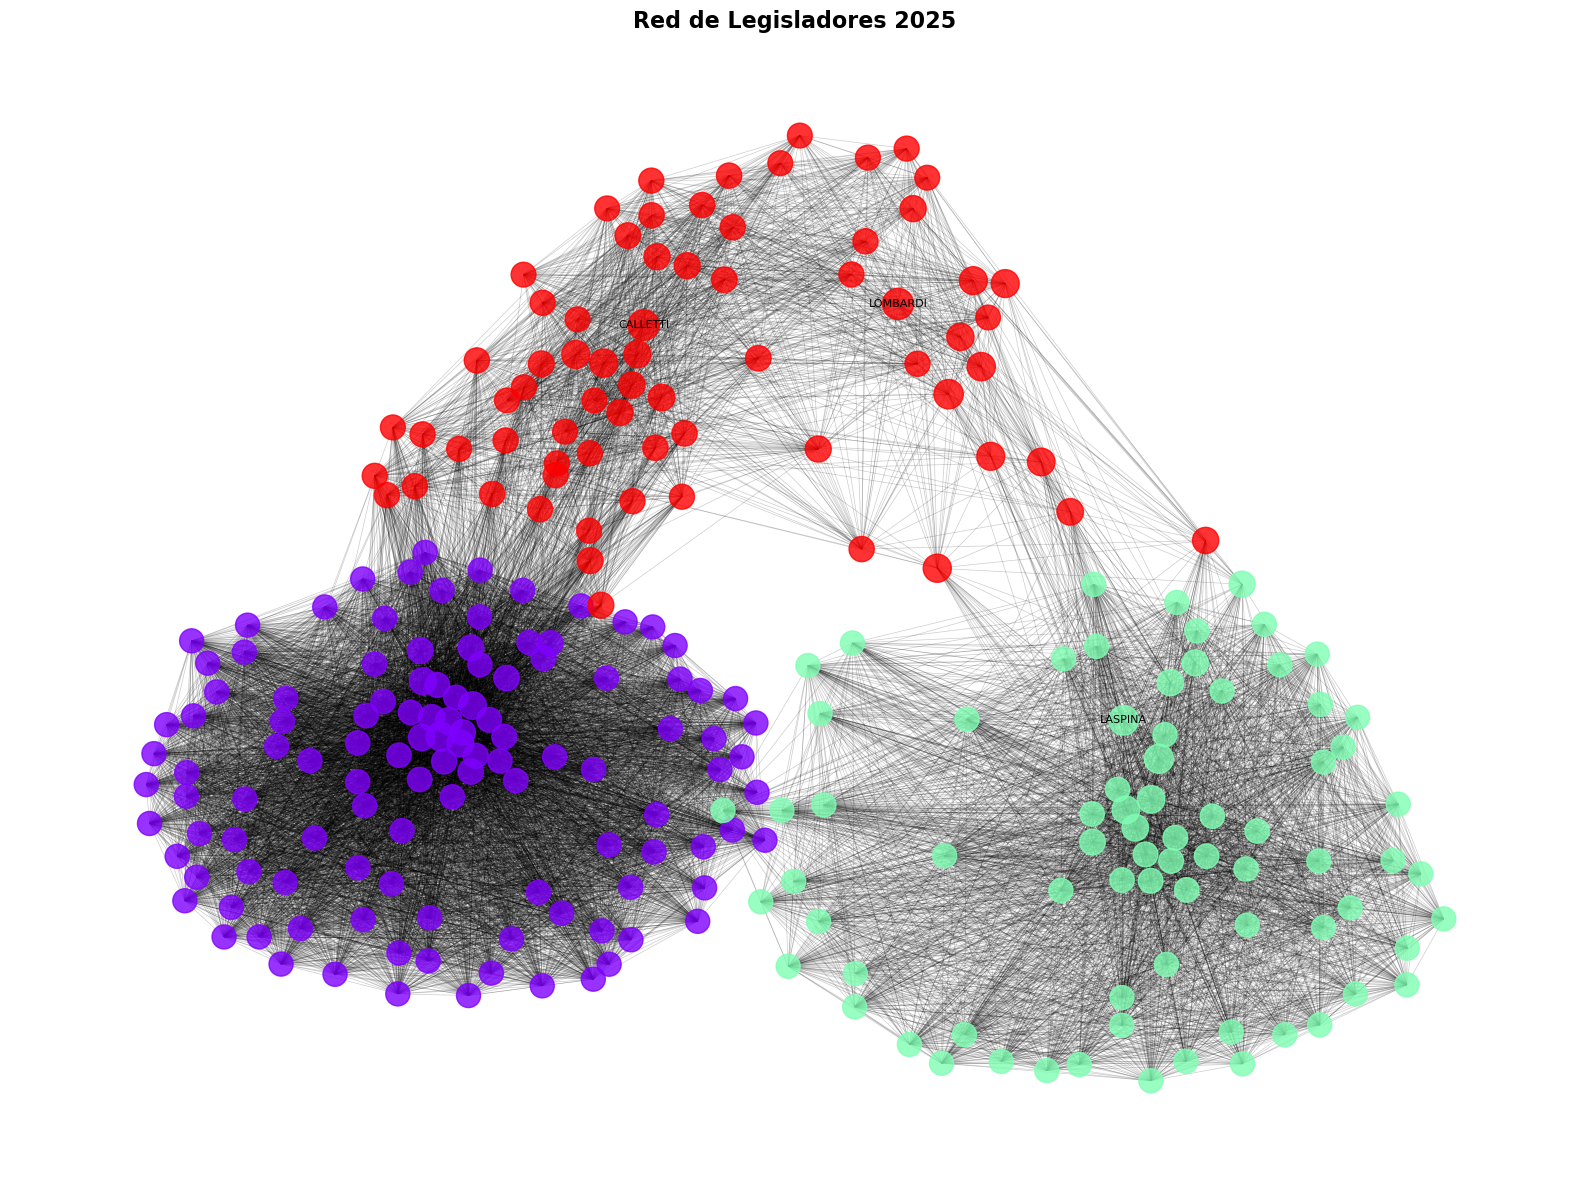

In [14]:
# Visualizar un año específico con matplotlib
def visualizar_grafo(G, titulo="Red de Legisladores"):
    """
    Visualiza un grafo con colores por comunidad.
    """
    plt.figure(figsize=(16, 12))
    
    # Layout spring (equivalente a layout_nicely en R)
    pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)
    
    # Extraer colores de nodos
    node_colors = [G.nodes[node].get('color', '#999999') for node in G.nodes()]
    
    # Tamaños de nodos proporcionales a betweenness
    node_sizes = [300 + 3000 * G.nodes[node].get('betweenness', 0) for node in G.nodes()]
    
    # Dibujar
    nx.draw_networkx_edges(G, pos, alpha=0.2, width=0.5)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, alpha=0.8)
    
    # Labels solo para nodos importantes
    labels = {node: node.split(',')[0] for node in G.nodes() 
              if G.nodes[node].get('betweenness', 0) > 0.05}
    nx.draw_networkx_labels(G, pos, labels, font_size=8)
    
    plt.title(titulo, fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Ejemplo: visualizar el año más reciente
if grafos_por_periodo:
    anio_reciente = max(grafos_por_periodo.keys())
    visualizar_grafo(
        grafos_por_periodo[anio_reciente],
        titulo=f"Red de Legisladores {anio_reciente}"
    )

In [15]:
# Función para convertir tipos numpy a JSON serializables
def convert_to_json_serializable(obj):
    """
    Convierte tipos numpy a tipos Python estándar para serialización JSON.
    """
    if hasattr(obj, 'item'):  # numpy types
        return obj.item()
    elif isinstance(obj, (str, int, float, bool)) or obj is None:
        return obj
    else:
        return str(obj)  # fallback para otros tipos

# Crear visualización interactiva con PyVis (si está disponible)
if grafos_por_periodo:
    def crear_vis_interactiva(G, anio, output_path):
        """
        Crea una visualización interactiva con PyVis.
        """
        # Crear una copia del grafo para modificar los atributos
        G_copy = G.copy()
        
        # Convertir atributos de nodos a tipos JSON serializables
        for node in G_copy.nodes():
            for attr_name, attr_value in G_copy.nodes[node].items():
                G_copy.nodes[node][attr_name] = convert_to_json_serializable(attr_value)
        
        # Convertir atributos de aristas a tipos JSON serializables
        for edge in G_copy.edges():
            for attr_name, attr_value in G_copy.edges[edge].items():
                G_copy.edges[edge][attr_name] = convert_to_json_serializable(attr_value)
        
        net = Network(height='800px', width='100%', bgcolor='#222222', font_color='white')
        net.from_nx(G_copy)
        
        # Configurar opciones
        net.set_options('''
        {
          "physics": {
            "forceAtlas2Based": {
              "gravitationalConstant": -50,
              "centralGravity": 0.01,
              "springLength": 100,
              "springConstant": 0.08
            },
            "maxVelocity": 50,
            "solver": "forceAtlas2Based"
          }
        }
        ''')
        
        # Guardar
        net.save_graph(output_path)
        print(f" Visualización interactiva guardada: {output_path}")
    
    # Crear visualización para el año más reciente
    anio_reciente = max(grafos_por_periodo.keys())
    ruta_html = os.path.join(carpeta_grafos, f"red_legisladores_{anio_reciente}.html")
    crear_vis_interactiva(grafos_por_periodo[anio_reciente], anio_reciente, ruta_html)

 Visualización interactiva guardada: legislativas/diputados/03_redes/grafos/red_legisladores_2025.html


## Análisis de Métricas por Año

In [16]:
# Top 10 legisladores por influencia colectiva (último año)
if len(df_grafos_pruned) > 0:
    ultimo_anio = df_grafos_pruned['anio'].max()
    top_ci = df_grafos_pruned[df_grafos_pruned['anio'] == ultimo_anio].nlargest(
        10, 'collective_influence'
    )[['legislador', 'bloque', 'collective_influence', 'betweenness', 'degree']]
    
    print(f"Top 10 legisladores por Influencia Colectiva ({ultimo_anio}):")
    print(top_ci.to_string(index=False))

Top 10 legisladores por Influencia Colectiva (2025):
               legislador                          bloque  collective_influence  betweenness  degree
 ARRIETA, LOURDES MICAELA                      Coherencia                873609     0.035552      70
              GOMEZ, JOSE             Union Por La Patria                873609     0.035552      70
         CALLETTI, PAMELA              Innovacion Federal                870330     0.063599      68
     QUETGLAS, FABIO JOSE      Ucr - Union Civica Radical                867181     0.026398      68
 SANCHEZ, ROBERTO ANTONIO      Ucr - Union Civica Radical                859180     0.022314      71
          ANTOLA, MARCELA         Democracia Para Siempre                856428     0.019677      70
SARAPURA, NATALIA SILVINA      Ucr - Union Civica Radical                834417     0.017749      70
          BARLETTA, MARIO                          Unidos                822732     0.015116      69
            VEGA, YOLANDA             